# Sumativa 2: validación, simulación y remuestreo
**MCDI501 · Universidad Andrés Bello · Grupo 7**  
**Integrantes:** Benjamín Araya, Alan Cañete, Patricio Cortez y Jorge Guaico.

Este cuaderno valida resultados propios de la Sumativa 1. Integra los tres scripts
de Patricio publicados en el commit `1484dd055fb99779932b85f0e87ac541400b893f`
y una capa adicional de interpretación, diagnóstico y trazabilidad. No entrena un modelo predictivo.

**Productos:** tablas y figuras en `results/03_sumativa2/`, archivo
`resultados_validados_s2.json`, síntesis para S3 y evidencia de ejecución diferenciada
entre Work y Windows. La fuente editable del informe está en `reports/03_sumativa2/`.

## Reproducción desde un kernel limpio
1. Obtener legítimamente el CSV original y ubicarlo en `data/raw/weatherAUS.csv`.
2. Preparar las dependencias de `requirements-sumativa2.txt` en el entorno del proyecto.
3. Seleccionar **Python (Grupo 7 - MCDI501)**, reiniciar el kernel y ejecutar todas las celdas.
4. Guardar el cuaderno y revisar la salida final y el registro de ejecución.

La sección de correlaciones vuelve a calcular 30.000 coeficientes sobre localidades completas;
puede tardar varios minutos. Muestra progreso cada 1.000 réplicas. No utiliza resultados
guardados para sustituir el cálculo. Semilla base: **20261018**; confianza individual: **95 %**.
Una ejecución en Work no acredita por sí sola ejecución en Windows.

In [1]:
from pathlib import Path
import os
import sys
import pandas as pd
from IPython.display import display, Image, Markdown

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / "src/cierre_sumativa2.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Abra el notebook dentro del proyecto con su carpeta src/.")
sys.path.insert(0, str(ROOT))
from src import cierre_sumativa2 as s2
print("Python:", sys.version.split()[0])
print("Proyecto localizado:", ROOT.name)
print("No se ejecutan comandos Git ni se modifican datos originales.")

Python: 3.12.0
Proyecto localizado: Proyecto-Lluvias-Australia-Grupo7
No se ejecutan comandos Git ni se modifican datos originales.


## 1. Identidad de datos y continuidad con S1
El archivo contiene observaciones localidad-fecha, con cobertura desigual y faltantes.
Se verifica su SHA-256 antes de analizarlo. No se imputan valores ni se eliminan globalmente filas.

Para las medias se conserva el estimando de S1:
\[\widehat\theta_X=\frac{1}{49}\sum_{\ell=1}^{49}\overline X_\ell.\]
Cada localidad tiene igual peso. Este promedio histórico observado difiere del promedio de
todas las filas y no es, por diseño, una estimación representativa de toda Australia.

Las tres medias y los intervalos clásicos se concilian con la tabla propia de S1;
las correlaciones con su matriz publicada. La diferencia de humedad y su prueba t se
recalculan con el mismo criterio de S1: casos conocidos en humedad y `RainTomorrow`.

In [2]:
ctx = s2.iniciar()
display(pd.Series(ctx["auditoria"], name="Auditoría"))
display(ctx["referencia_s1"].round(6))

CSV identificado; S1 conciliada; no se imputa ni modifica el original.


filas                                                                                 145460
columnas                                                                                  23
localidades                                                                               49
fecha_minima                                                                      2007-11-01
fecha_maxima                                                                      2017-06-25
objetivo_conocido                                                                     142193
lluvia_yes                                                                             31877
porcentaje_yes_etiquetas_conocidas                                                 22.418122
faltantes_sunshine_pct                                                             48.009762
faltantes_evaporation_pct                                                          43.166506
localidades_sunshine_totalmente_ausente                               

,Variable,Localidades,Media local,Desv. entre localidades,Error estándar,IC 95% inferior,IC 95% superior
0,Humidity3pm,49,51.246693,11.217162,1.602452,48.024747,54.468638
1,MaxTemp,49,23.388345,4.056094,0.579442,22.223299,24.553391
2,MinTemp,49,12.258711,3.950826,0.564404,11.123901,13.393520


## 2. Bootstrap de tres parámetros: unidad, intervalos y supuestos
Se extraen con reemplazo 49 **medias locales completas** y se calcula su promedio,
10.000 veces por variable. El método percentil utiliza los cuantiles 2,5 y 97,5 %.
BCa ajusta por sesgo y aceleración mediante SciPy. Se compara con el intervalo t de S1,
con 48 grados de libertad. Son IC individuales, no una cobertura simultánea para los tres parámetros.

**Justificación y límites:** agregar por localidad evita tratar los días como réplicas
independientes. El bootstrap modela localidades comparables e independientes entre sí;
la selección de las estaciones y la independencia espacial no están demostradas.
Los historiales observados quedan condicionados: remuestrear sus medias no genera
nuevos días ni incorpora explícitamente la incertidumbre de cada media local.

El percentil y BCa usan flujos reproducibles distintos: semillas `20261018+i`
y `20261118+i`, respectivamente, con `i=0,1,2` según el orden Humidity3pm, MaxTemp,
MinTemp. Por ello, las diferencias entre extremos de ambos métodos también contienen
variación Monte Carlo. BCa no garantiza una cobertura superior cuando fallan los supuestos.


Humedad a las 3 PM (Humidity3pm)
  Estimacion S1: 51.246693 %
  IC clasico:    [48.024747, 54.468638]
  IC percentil:  [48.045099, 54.349061]
  IC BCa:        [48.041600, 54.256064]

Temperatura maxima (MaxTemp)
  Estimacion S1: 23.388345 °C
  IC clasico:    [22.223299, 24.553391]
  IC percentil:  [22.275148, 24.514247]
  IC BCa:        [22.299708, 24.571460]

Temperatura minima (MinTemp)
  Estimacion S1: 12.258711 °C
  IC clasico:    [11.123901, 13.393520]
  IC percentil:  [11.188268, 13.375942]
  IC BCa:        [11.260243, 13.479809]



=== RESUMEN COMPARATIVO ===
   Variable  IC_clasico_inferior  IC_clasico_superior  IC_percentil_inferior  IC_percentil_superior  IC_BCa_inferior  IC_BCa_superior
Humidity3pm            48.024747            54.468638              48.045099              54.349061        48.041600        54.256064
    MaxTemp            22.223299            24.553391              22.275148              24.514247        22.299708        24.571460
    MinTemp            11.123901            13.393520              11.188268              13.375942        11.260243        13.479809

Archivos generados:
C:\Users\benja\OneDrive\Escritorio\Proyecto-Lluvias-Australia-Grupo7\results\03_sumativa2\tables\bootstrap_ic_s2_resumen.csv
C:\Users\benja\OneDrive\Escritorio\Proyecto-Lluvias-Australia-Grupo7\results\03_sumativa2\tables\bootstrap_ic_s2_distribuciones.csv
C:\Users\benja\OneDrive\Escritorio\Proyecto-Lluvias-Australia-Grupo7\results\03_sumativa2\figures\bootstrap_ic_s2_distribuciones.png

Proceso finalizado corr

,Variable,Estimacion_S1,IC_clasico_inferior,IC_clasico_superior,IC_percentil_inferior,IC_percentil_superior,IC_BCa_inferior,IC_BCa_superior
0,Humidity3pm,51.246693,48.024747,54.468638,48.045099,54.349061,48.041600,54.256064
1,MaxTemp,23.388345,22.223299,24.553391,22.275148,24.514247,22.299708,24.571460
2,MinTemp,12.258711,11.123901,13.393520,11.188268,13.375942,11.260243,13.479809


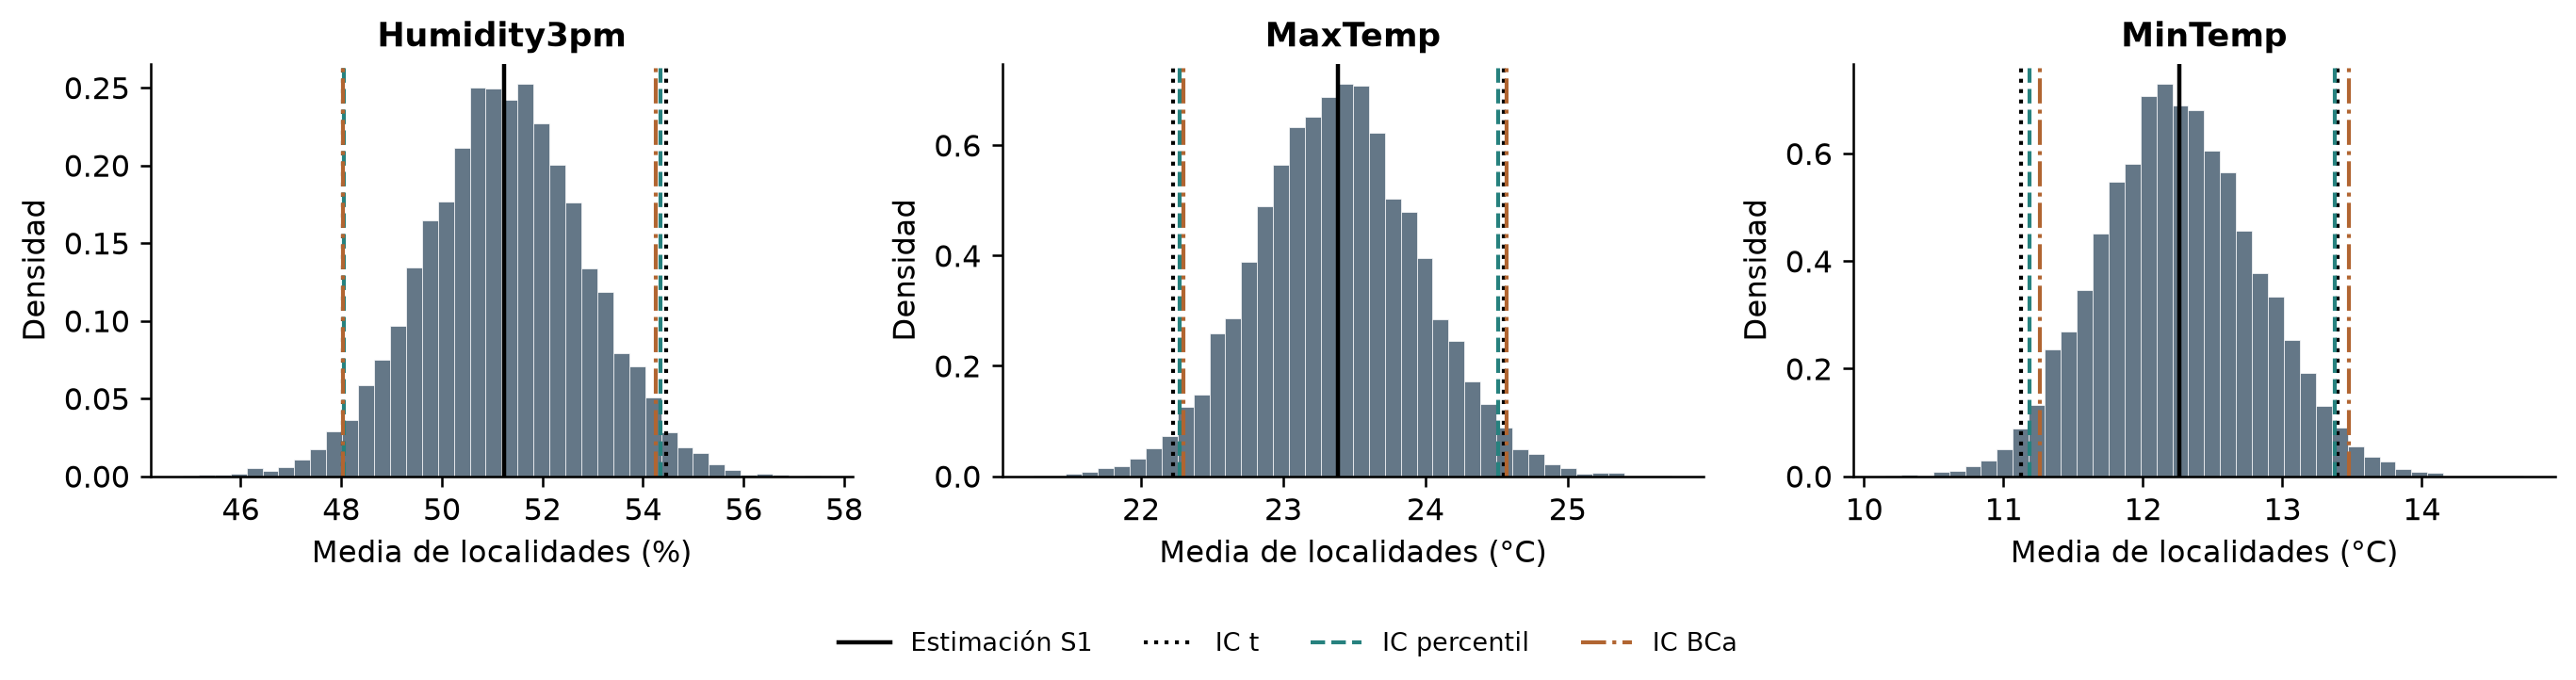

In [3]:
bootstrap = s2.ejecutar_bootstrap(ctx)
columns = ["Variable", "Estimacion_S1", "IC_clasico_inferior", "IC_clasico_superior",
           "IC_percentil_inferior", "IC_percentil_superior", "IC_BCa_inferior", "IC_BCa_superior"]
display(bootstrap[columns].round(6))
display(Image(filename=str(s2.FIGS / "s2_bootstrap_medias.png")))

In [4]:
comparison = bootstrap[["Variable", "Ancho_clasico", "Ancho_percentil", "Ancho_BCa"]].copy()
comparison["Cambio_ancho_percentil_pct"] = 100 * (comparison.Ancho_percentil / comparison.Ancho_clasico - 1)
comparison["Cambio_ancho_BCa_pct"] = 100 * (comparison.Ancho_BCa / comparison.Ancho_clasico - 1)
display(comparison.round(4))
display(Markdown("Los tres métodos producen intervalos ampliamente solapados. "
                 "Los cambios de anchura se cuantifican arriba; el solapamiento respalda "
                 "concordancia dentro de este modelo, pero no prueba cobertura real ni "
                 "elimina sesgo por faltantes, cobertura temporal o dependencia entre estaciones."))

,Variable,Ancho_clasico,Ancho_percentil,Ancho_BCa,Cambio_ancho_percentil_pct,Cambio_ancho_BCa_pct
0,Humidity3pm,6.4439,6.3040,6.2145,-2.1715,-3.5604
1,MaxTemp,2.3301,2.2391,2.2718,-3.9051,-2.5038
2,MinTemp,2.2696,2.1877,2.2196,-3.6105,-2.2054


Los tres métodos producen intervalos ampliamente solapados. Los cambios de anchura se cuantifican arriba; el solapamiento respalda concordancia dentro de este modelo, pero no prueba cobertura real ni elimina sesgo por faltantes, cobertura temporal o dependencia entre estaciones.

## 3. Permutación mediante cambios de signo
Se conserva la hipótesis bilateral de S1 sobre diferencias locales:
\[D_\ell=\overline H_{\ell,Yes}-\overline H_{\ell,No},\quad
H_0:E(D_\ell)=0,\qquad H_1:E(D_\ell)\ne0.\]
El estadístico es la media de las 49 diferencias, en **puntos porcentuales de humedad**.
En cada réplica se generan signos independientes equiprobables \(s_\ell\in\{-1,+1\}\)
y se calcula \(T^*=49^{-1}\sum_\ell s_\ell D_\ell\).

**Condición adicional esencial:** para que la distribución de cambios de signo sea
válida bajo H0, se supone simetría alrededor de cero de las diferencias nulas e
independencia entre localidades. La igualdad de medias por sí sola no garantiza
esa invariancia. La lluvia no se asignó aleatoriamente, por lo que no se presenta
como una prueba exacta sustentada en un diseño experimental.

El diagnóstico Q-Q y Shapiro de las diferencias observadas describe su forma.
No demostrarán simetría de la distribución nula, intercambiabilidad ni independencia.
La comparación con t es un análisis de sensibilidad condicional a esos supuestos.
Se evitan permutaciones arbitrarias de filas diarias, que romperían su estructura.

SUMATIVA 2: VALIDACIÓN POR PERMUTACIÓN Y ESTABILIDAD
Filas cargadas: 145,460
Localidades identificadas: 49
Semilla aleatoria: 20261018
Permutaciones: 10,000
Réplicas bootstrap por correlación: 10,000

PUNTO 2: PRUEBA DE HIPÓTESIS POR PERMUTACIÓN
Permutaciones completadas: 2,000/10,000
Permutaciones completadas: 4,000/10,000
Permutaciones completadas: 6,000/10,000
Permutaciones completadas: 8,000/10,000
Permutaciones completadas: 10,000/10,000



Resultados de la prueba de permutación:
   variable        grupo_yes        grupo_no unidad_analisis  n_localidades  n_permutaciones  media_diferencias_pp  ic95_t_inferior  ic95_t_superior  estadistico_t  grados_libertad  p_parametrico_t  extremos_permutacion  p_permutacion  alpha decision_parametrica decision_permutacion  semilla
Humidity3pm RainTomorrow=Yes RainTomorrow=No        Location             49            10000             20.076901        18.471589        21.682214      25.146084               48     2.747108e-29                     0         0.0001   0.05          Rechazar H0          Rechazar H0 20261018
Tiempo punto 2: 0.4 segundos

PUNTO 3: ESTABILIDAD DE CORRELACIONES

Procesando MaxTemp vs. Temp3pm: n=141,589; localidades=49


  MaxTemp vs. Temp3pm: 1,000/10,000 réplicas


  MaxTemp vs. Temp3pm: 2,000/10,000 réplicas


  MaxTemp vs. Temp3pm: 3,000/10,000 réplicas


...

  Humidity3pm vs. Rainfall: 8,000/10,000 réplicas


  Humidity3pm vs. Rainfall: 9,000/10,000 réplicas


  Humidity3pm vs. Rainfall: 10,000/10,000 réplicas
  Spearman S1: 0.4436
  IC bootstrap 95 %: [0.4107, 0.4739]
  IC incluye cero: False
  Tiempo: 224.5 segundos



ANÁLISIS COMPLETADO

Tabla de permutación:
results\03_sumativa2\tables\prueba_permutacion_humedad.csv

Tabla de correlaciones:
results\03_sumativa2\tables\estabilidad_correlaciones_bootstrap.csv

Figuras generadas:
results\03_sumativa2\figures\permutacion_humedad.png
results\03_sumativa2\figures\distribuciones_bootstrap_correlaciones.png
results\03_sumativa2\figures\intervalos_confianza_correlaciones.png

Resumen:
results\03_sumativa2\resumen_validacion_s2.txt


,valor
variable,Humidity3pm
grupo_yes,RainTomorrow=Yes
grupo_no,RainTomorrow=No
unidad_analisis,Location
n_localidades,49
n_permutaciones,10000
media_diferencias_pp,20.076901
ic95_t_inferior,18.471589
ic95_t_superior,21.682214
estadistico_t,25.146084


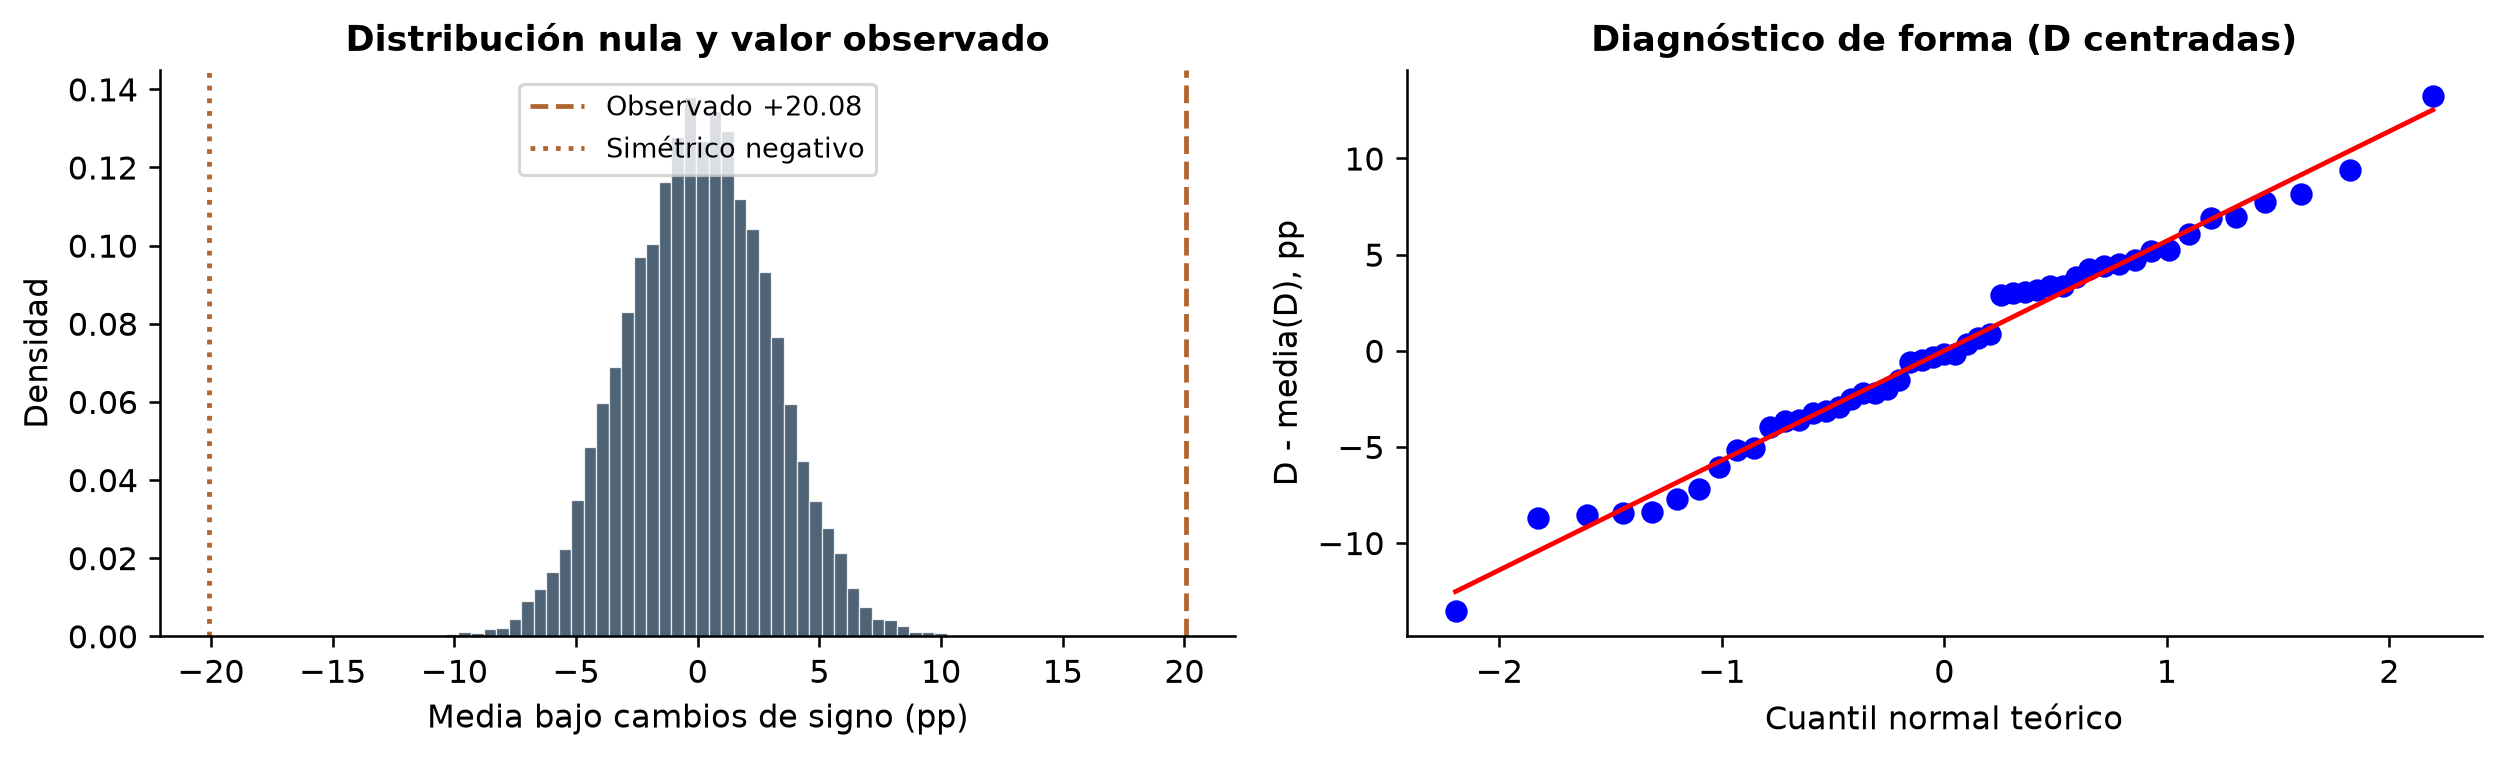

In [5]:
permutation, correlations = s2.ejecutar_permutaciones_correlaciones(ctx)
display(permutation)
display(Image(filename=str(s2.FIGS / "s2_permutacion_diagnostico.png")))

In [6]:
p = ctx["permutacion"]
display(Markdown(
    f"La diferencia media es **{p.media_diferencias_pp:.4f} pp**; "
    f"t={p.estadistico_t:.4f}, gl={int(p.grados_libertad)}, "
    f"p paramétrico={p.p_parametrico_t:.6g}. Con "
    f"{int(p.n_permutaciones):,} cambios de signo se observaron "
    f"{int(p.extremos_permutacion)} réplicas tan extremas. La corrección "
    f"(r+1)/(B+1) da **p={p.p_permutacion:.8f}**. "
    "Ambos enfoques rechazan H0 al 5 % bajo sus supuestos. El valor de permutación "
    "está en el mínimo resoluble con 10.000 réplicas: no equivale al valor p paramétrico "
    "ni justifica reportar p=0. La humedad mayor se asocia a lluvia posterior; "
    "no representa un aumento de igual tamaño en probabilidad ni demuestra causalidad."))

La diferencia media es **20.0769 pp**; t=25.1461, gl=48, p paramétrico=2.74711e-29. Con 10,000 cambios de signo se observaron 0 réplicas tan extremas. La corrección (r+1)/(B+1) da **p=0.00009999**. Ambos enfoques rechazan H0 al 5 % bajo sus supuestos. El valor de permutación está en el mínimo resoluble con 10.000 réplicas: no equivale al valor p paramétrico ni justifica reportar p=0. La humedad mayor se asocia a lluvia posterior; no representa un aumento de igual tamaño en probabilidad ni demuestra causalidad.

## 4. Estabilidad de tres correlaciones de S1
Se conservan los pares MaxTemp/Temp3pm, Humidity3pm/Sunshine y Humidity3pm/Rainfall.
Se excluyen faltantes **por par**, sin imputar. Cada réplica extrae localidades con
reemplazo y concatena todos sus registros válidos; se vuelven a calcular los rangos
de Spearman. Se realizan 10.000 réplicas por par e IC percentil al 95 %.

Conservar conglomerados completos mantiene juntos los días de cada localidad en la
remuestra. No los supone independientes dentro del conglomerado, pero tampoco genera
trayectorias futuras ni resuelve dependencia entre localidades. El coeficiente es
agrupado sobre filas: las localidades con más registros conservan mayor peso dentro
del cálculo. No es el promedio con igual peso de correlaciones locales.

Cada histograma utiliza una escala ajustada a su propia distribución. La exclusión
de cero se evalúa en la tabla y no se fuerza una línea en cero que oculte la forma.

,variable_x,variable_y,n_pares_original,n_localidades,rho_spearman_s1,ic95_inferior,ic95_superior,amplitud_ic95,ic95_incluye_cero
0,MaxTemp,Temp3pm,141589,49,0.984476,0.981228,0.986821,0.005592,False
1,Humidity3pm,Sunshine,74497,30,-0.620349,-0.659534,-0.580313,0.079221,False
2,Humidity3pm,Rainfall,138569,49,0.443635,0.410718,0.473916,0.063198,False


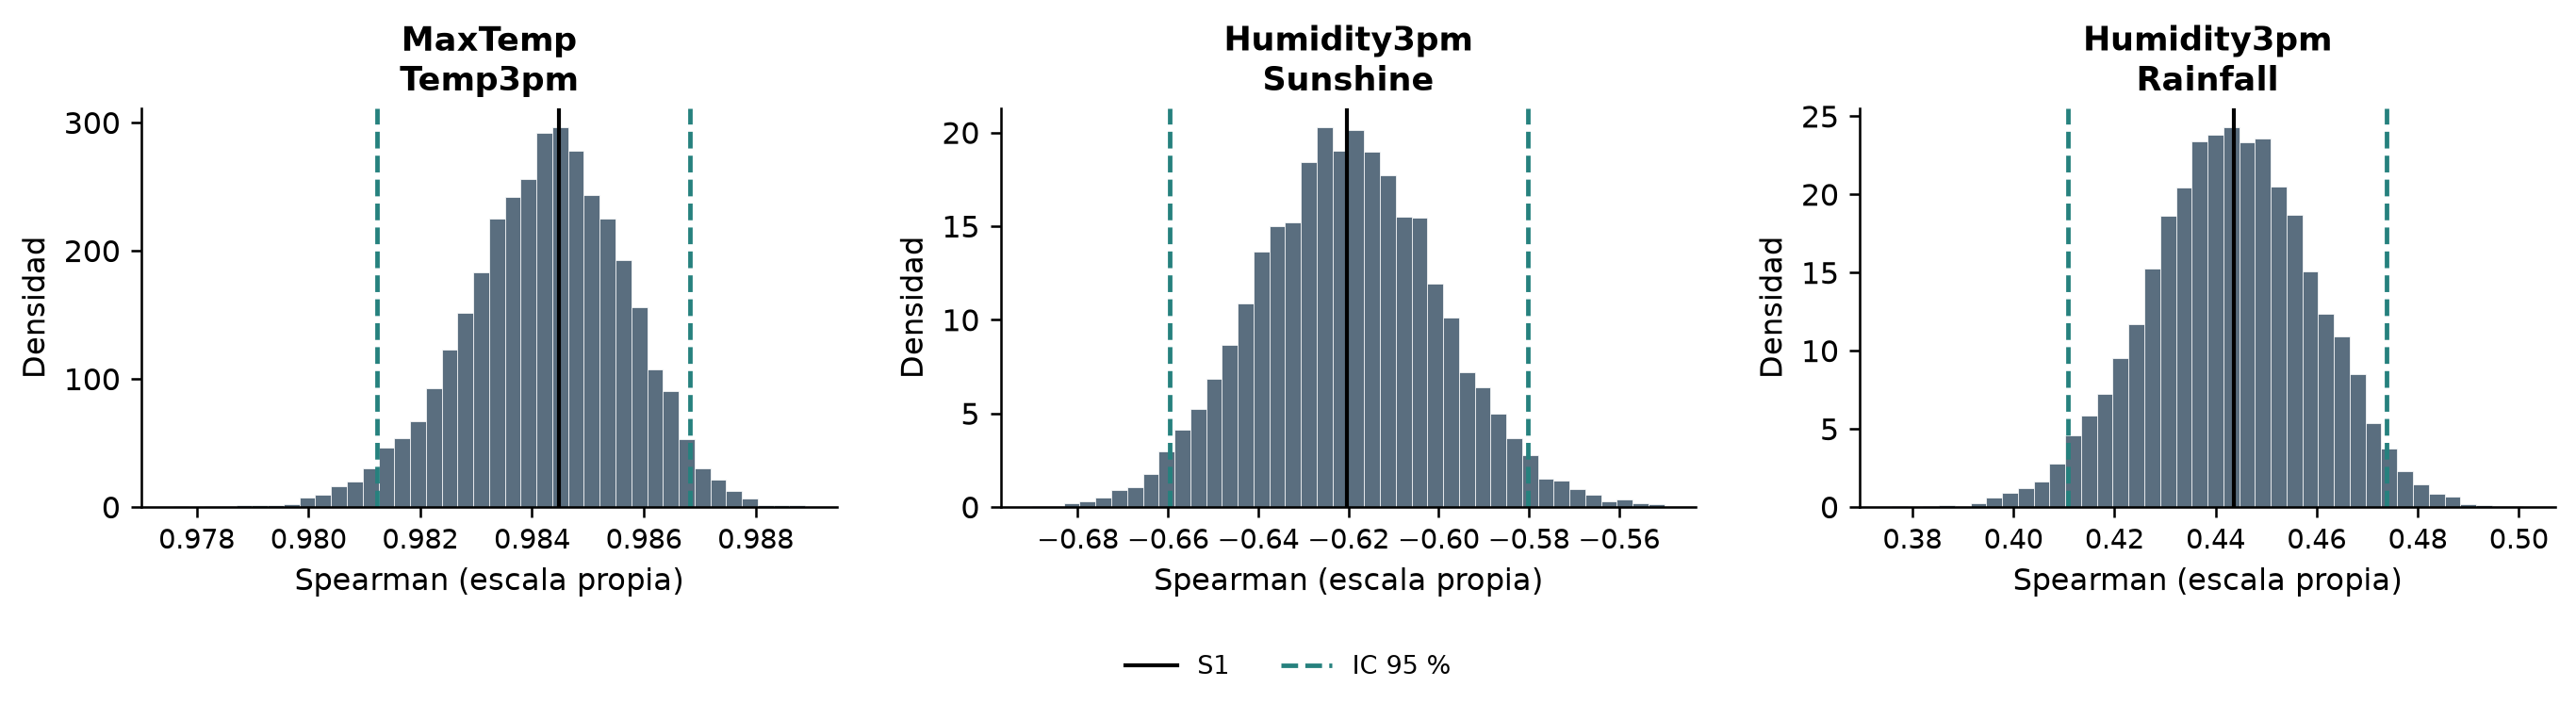

In [7]:
display(correlations[["variable_x", "variable_y", "n_pares_original", "n_localidades",
                      "rho_spearman_s1", "ic95_inferior", "ic95_superior", "amplitud_ic95",
                      "ic95_incluye_cero"]].round(6))
display(Image(filename=str(s2.FIGS / "s2_correlaciones_distribuciones.png")))

Los tres intervalos excluyen cero: hay estabilidad del **signo** bajo este
remuestreo. MaxTemp/Temp3pm sugiere fuerte redundancia, que se comprobará dentro del
entrenamiento en una fase posterior. Humedad/sol presenta una asociación negativa,
pero solo se observan 30 localidades para ese par; su intervalo no avala extrapolar a
las 49 estaciones. La asociación humedad/lluvia es positiva, con magnitud cuya
sensibilidad se evalúa en la sección 6. No se usa una anchura arbitraria del IC para
declarar robustez general. Las correlaciones agrupadas pueden mezclar efectos
estacionales y geográficos y no establecen causalidad ni rendimiento predictivo.

## 5. Monte Carlo: escenario basado exclusivamente en parámetros de S1
Se simulan 10.000 muestras hipotéticas de 49 diferencias locales independientes:
\[D^*_{b\ell}\sim N(\widehat\mu_D,\widehat\sigma_D^2),\qquad
\overline D_b^*=49^{-1}\sum_\ell D^*_{b\ell}.\]
La media y desviación entre las 49 diferencias se calculan con el mismo conjunto y
definición de S1; no se incorporan parámetros de otro dataset. La normalidad es una
aproximación exploratoria compatible con el diagnóstico de forma de S1.

**Escenario de decisión:** evaluar cuánto variaría la diferencia media de humedad en
muestras de localidades comparables. Esto ayuda a valorar si su magnitud descriptiva
resulta persistente antes de considerar la humedad como candidato a predictor.
No simula el tiempo atmosférico ni produce probabilidades de lluvia individual.

Se compara la dispersión de medias simuladas con el valor teórico
\(\widehat\sigma_D/\sqrt{49}\), y el error Monte Carlo de su media con
\(s(\overline D^*)/\sqrt{10\,000}\). Los percentiles describen el rango central
del escenario condicionado a parámetros fijos: **no son un IC del parámetro desconocido**.


PUNTO 4: Monte Carlo
                                                                      escenario                                                    distribucion  n_localidades_S1  media_diferencias_S1_pp  sd_diferencias_entre_localidades_pp  localidades_por_muestra  iteraciones  media_simulada_pp  sd_medias_simuladas_pp   p2_5_pp  p97_5_pp  semilla
Media de diferencias locales en muestras hipotéticas de localidades comparables Normal(mu_hat, sd_hat), estimados de las diferencias locales S1                49                20.076901                             5.588875                       49        10000          20.072868                 0.79417 18.503248 21.617736 20261018

Convergencia:
 iteraciones  media_acumulada      p2_5     p97_5  ancho_intervalo
         100        20.210042 18.744134 21.581195         2.837061
         500        20.097192 18.551377 21.613707         3.062330
        1000        20.054946 18.534629 21.623042         3.088413
        2500        20.0735

,0
escenario,Media de diferencias locales en muestras hipot...
distribucion,"Normal(mu_hat, sd_hat), estimados de las difer..."
n_localidades_S1,49
media_diferencias_S1_pp,20.076901
sd_diferencias_entre_localidades_pp,5.588875
localidades_por_muestra,49
iteraciones,10000
media_simulada_pp,20.072868
sd_medias_simuladas_pp,0.79417
p2_5_pp,18.503248


,0
iteraciones,10000
media_objetivo_pp,20.076901
media_montecarlo_pp,20.072868
sd_medias_simuladas_pp,0.79417
sd_teorica_media_pp,0.798411
mcse_media_simulada_pp,0.007942
diferencia_media_simulada_objetivo_pp,-0.004034
diferencia_en_unidades_mcse,-0.507909
tipo_intervalo_simulado,Intervalo central de medias hipotéticas; no IC...


,iteraciones,media_acumulada,p2_5,p97_5,ancho_intervalo
0,100,20.210042,18.744134,21.581195,2.837061
1,500,20.097192,18.551377,21.613707,3.062330
2,1000,20.054946,18.534629,21.623042,3.088413
3,2500,20.073571,18.527226,21.610721,3.083495
4,5000,20.074285,18.534687,21.617547,3.082860
5,10000,20.072868,18.503248,21.617736,3.114488


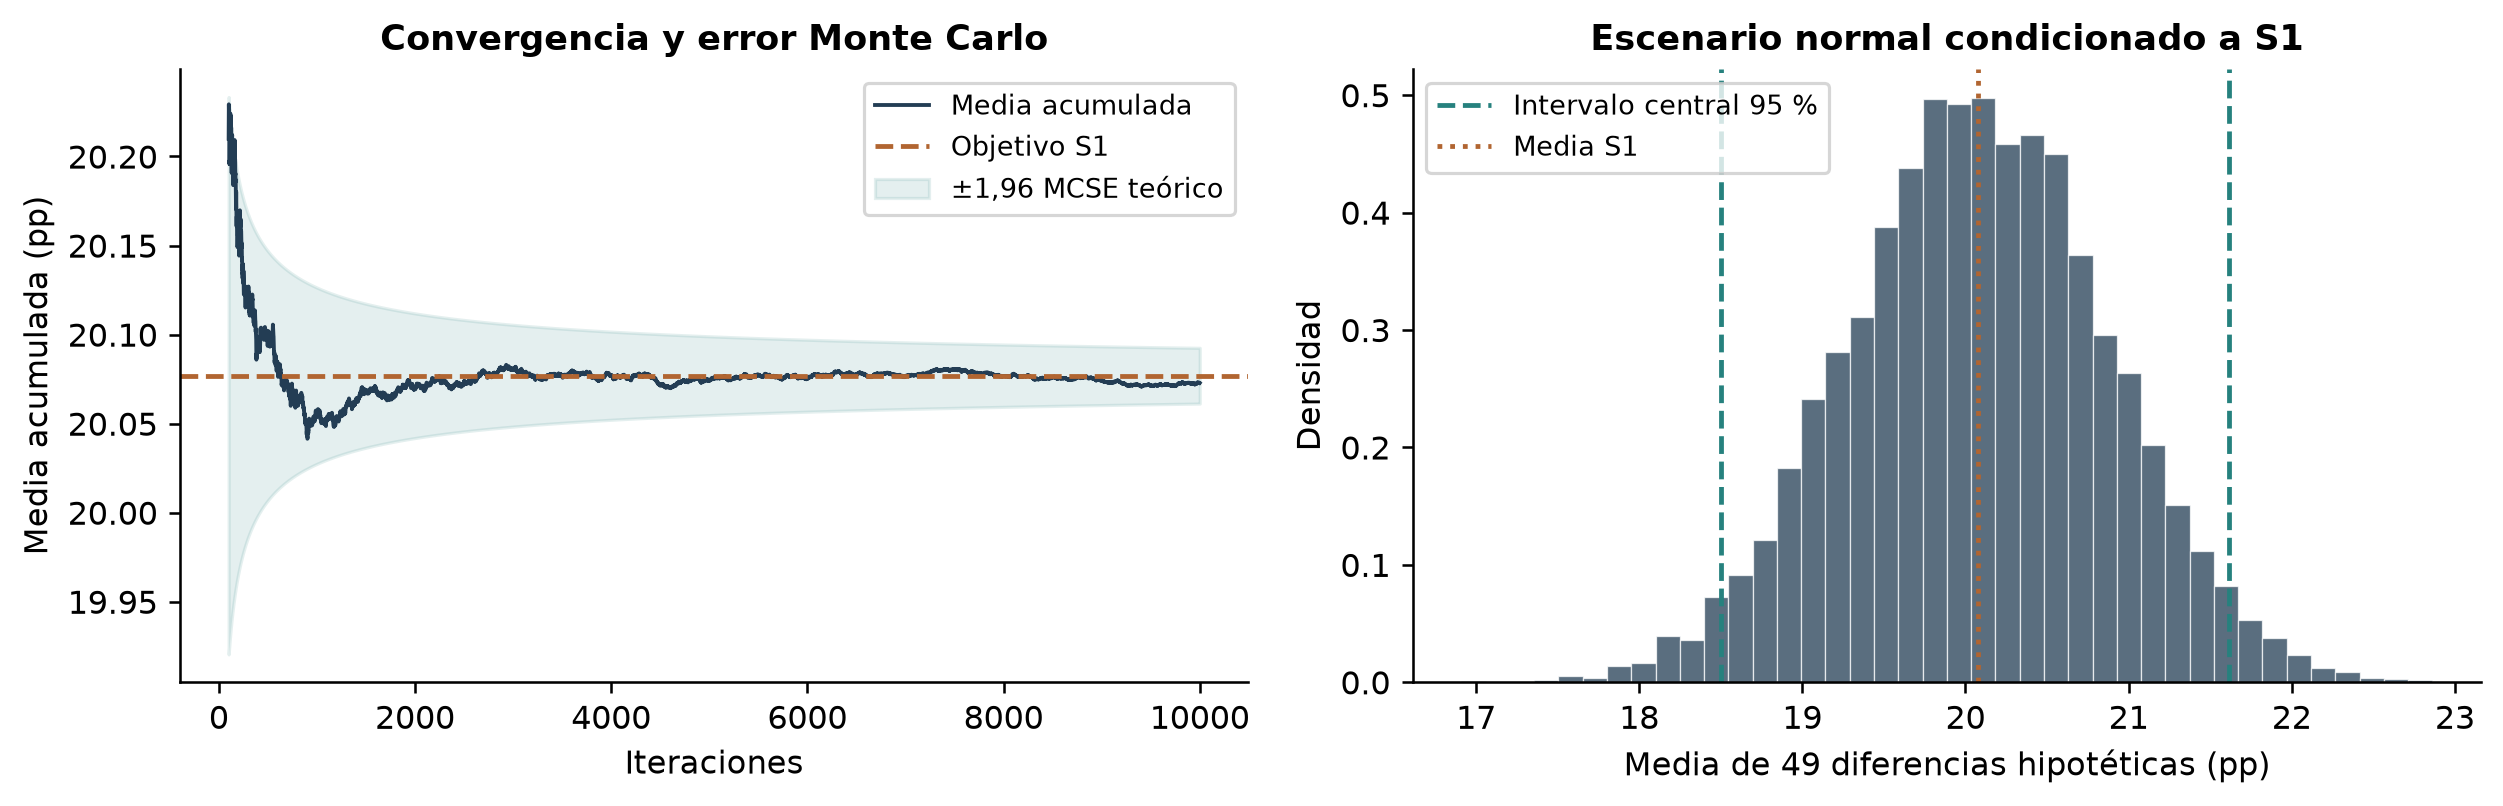

In [8]:
mc_diagnostic, robust_correlations = s2.ejecutar_montecarlo_robustez(ctx)
display(s2.read_table("monte_carlo_resumen.csv").T)
display(mc_diagnostic.T)
display(s2.read_table("monte_carlo_convergencia.csv").round(6))
display(Image(filename=str(s2.FIGS / "s2_montecarlo.png")))

In [9]:
m = ctx["mc_diagnostico"]
display(Markdown(
    f"La media simulada es **{m['media_montecarlo_pp']:.5f} pp**, frente a "
    f"{m['media_objetivo_pp']:.5f} pp de S1. La discrepancia es "
    f"{m['diferencia_media_simulada_objetivo_pp']:.5f} pp, equivalente a "
    f"{m['diferencia_en_unidades_mcse']:.2f} errores Monte Carlo "
    f"(MCSE={m['mcse_media_simulada_pp']:.5f} pp). "
    "La convergencia numérica es compatible con el objetivo del escenario; "
    "sus cuantiles aún fluctúan y 10.000 iteraciones no demuestran que el modelo "
    "normal o la independencia describan el clima real. La simulación tampoco "
    "propaga incertidumbre en los parámetros que se fijaron al inicio."))

La media simulada es **20.07287 pp**, frente a 20.07690 pp de S1. La discrepancia es -0.00403 pp, equivalente a -0.51 errores Monte Carlo (MCSE=0.00794 pp). La convergencia numérica es compatible con el objetivo del escenario; sus cuantiles aún fluctúan y 10.000 iteraciones no demuestran que el modelo normal o la independencia describan el clima real. La simulación tampoco propaga incertidumbre en los parámetros que se fijaron al inicio.

## 6. Robustez: localidades influyentes y filtro diagnóstico
Se remuestrean 10.000 medias de las 49 diferencias locales y se aplica jackknife
omitiendo una localidad cada vez. La influencia se expresa como cambio en puntos
porcentuales respecto de la media completa. Una localidad influyente no se considera
errónea por tener un clima distinto.

Para las correlaciones se compara Spearman con Kendall tau-b y se evalúa un filtro
por cercas de Tukey (1,5 IQR) en ambas variables del par. Los coeficientes de Kendall
y Spearman no comparten una escala numérica equivalente: se compara la dirección y
la evidencia de asociación, sin exigir igualdad de magnitudes.

**El filtro es exclusivamente diagnóstico.** Se conservan los extremos meteorológicos
plausibles y todas las filas del archivo original. Se exportan los límites y los
conteos excluidos para precisar qué población observada describe el análisis restringido.

,0
n_localidades,4.900000e+01
media_diferencia_pp,2.007690e+01
ic95_t_inferior,1.847159e+01
ic95_t_superior,2.168221e+01
ic95_bootstrap_inferior,1.851720e+01
ic95_bootstrap_superior,2.161670e+01
media_jackknife_min,1.980069e+01
media_jackknife_max,2.035836e+01
diferencias_locales_positivas,4.900000e+01
max_cambio_absoluto_jackknife_pp,2.814627e-01


,localidad_omitida,media_sin_localidad_pp,cambio_vs_media_completa_pp,cambio_absoluto_pp
0,Albany,20.358364,0.281463,0.281463
1,AliceSprings,19.800686,-0.276216,0.276216
2,Cobar,19.880769,-0.196132,0.196132
3,NorfolkIsland,20.258053,0.181152,0.181152
4,Portland,20.255228,0.178327,0.178327
5,Melbourne,20.252214,0.175312,0.175312
6,Hobart,20.251648,0.174747,0.174747
7,Uluru,19.907622,-0.169279,0.169279
8,Moree,19.915625,-0.161276,0.161276
9,Walpole,20.237280,0.160379,0.160379


,0
n_localidades,49
asimetria_diferencias,-0.075702
shapiro_W,0.988352
shapiro_p,0.905873
diferencias_fuera_tukey,0
independencia_espacial_verificada,False
intercambiabilidad_signos_verificada_por_diseno,False
alcance,Diagnóstico de forma; no prueba independencia ...


,variable_x,variable_y,n_original,limite_inferior_x,limite_superior_x,limite_inferior_y,limite_superior_y,n_excluido_diagnostico,pct_excluido,uso
0,MaxTemp,Temp3pm,141589,2.45,43.65,1.90,41.10,782,0.552303,Sensibilidad; no regla de limpieza ni identifi...
1,Humidity3pm,Sunshine,74497,-6.00,106.00,-3.65,19.15,0,0.000000,Sensibilidad; no regla de limpieza ni identifi...
2,Humidity3pm,Rainfall,138569,-6.50,109.50,-1.20,2.00,24790,17.890004,Sensibilidad; no regla de limpieza ni identifi...


,variable_x,variable_y,n_completo,spearman_completo,kendall_tau_b_completo,n_dentro_cercas_tukey,porcentaje_excluido_solo_sensibilidad,spearman_sensibilidad_tukey,cambio_spearman,signo_spearman_kendall_coincide,conclusion_integrada,cambio_relativo_magnitud_pct
0,MaxTemp,Temp3pm,141589,0.984476,0.911737,140807,0.552303,0.984217,-0.000259,True,Signo estable y magnitud poco sensible al filt...,-0.026297
1,Humidity3pm,Sunshine,74497,-0.620349,-0.449171,74497,0.000000,-0.620349,0.000000,True,Signo estable en 30 localidades; filtro no eli...,0.000000
2,Humidity3pm,Rainfall,138569,0.443635,0.340296,113779,17.890004,0.307406,-0.136229,True,Signo positivo estable; magnitud sensible al r...,-30.707398


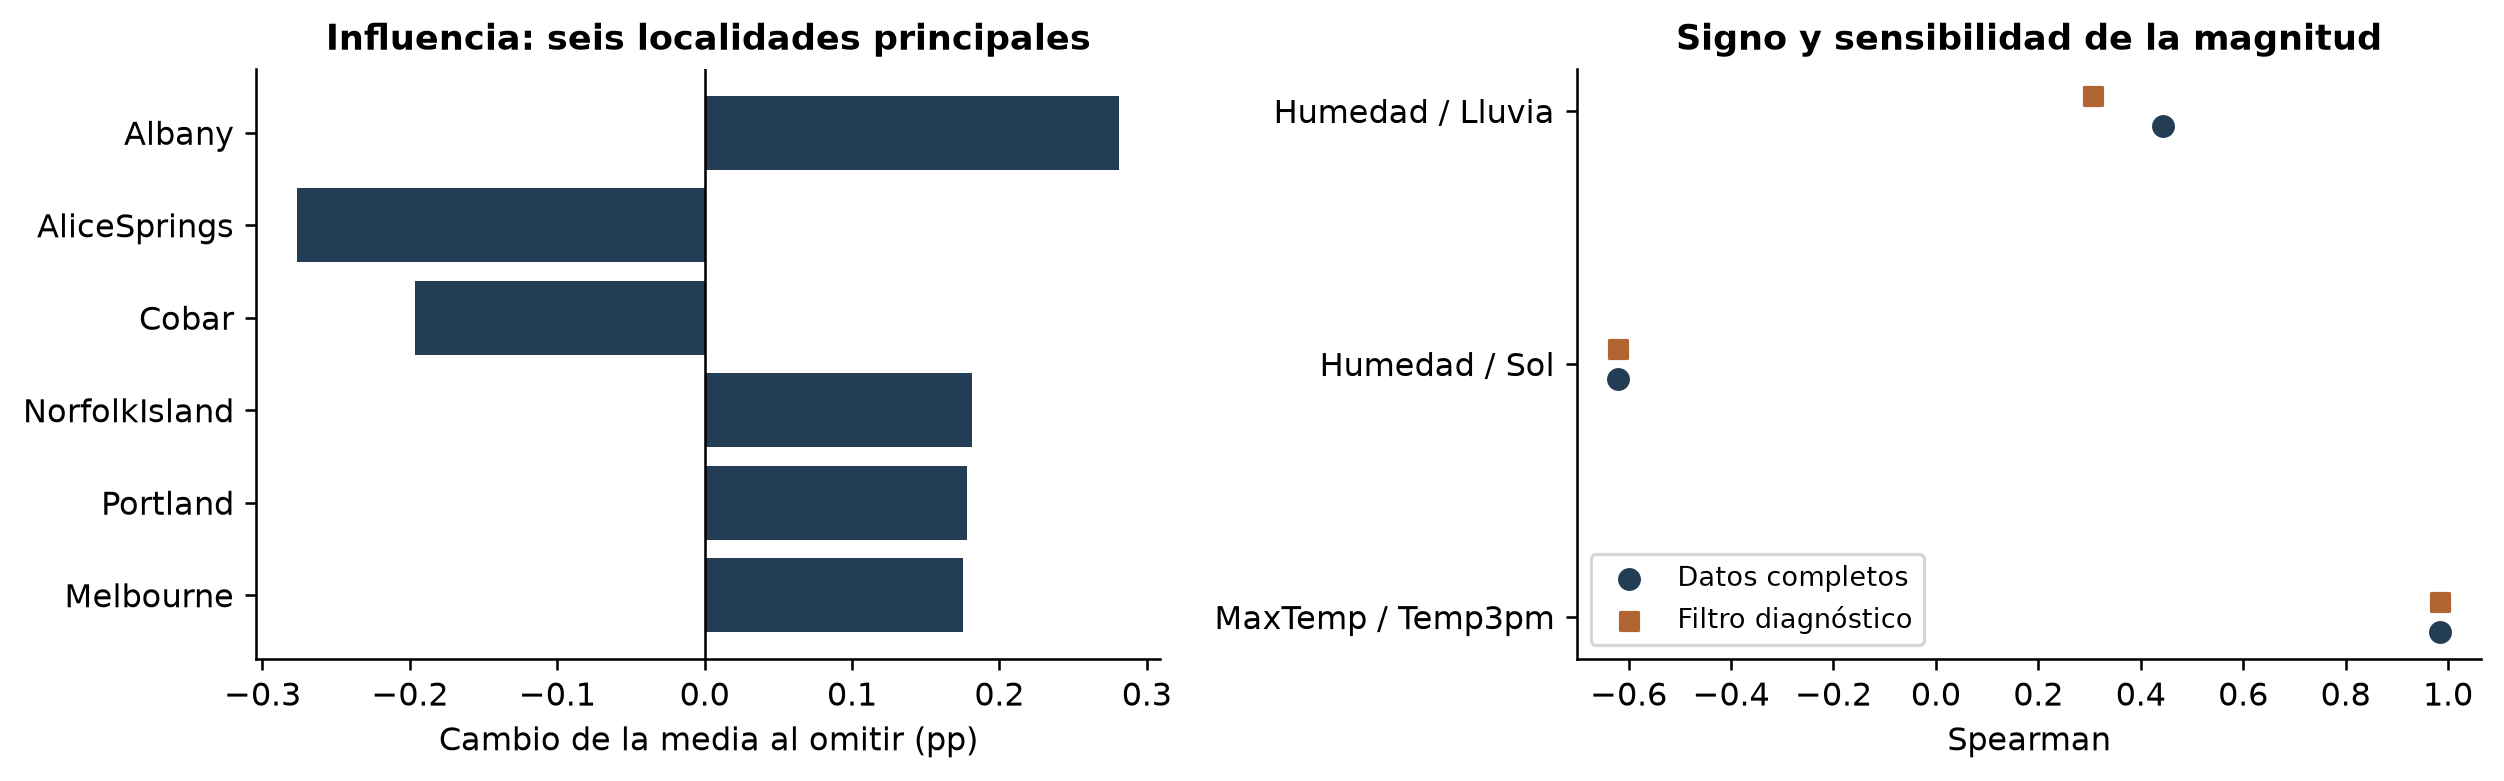

In [10]:
display(s2.read_table("robustez_diferencia_humedad.csv").T)
display(ctx["jackknife"].head(10).round(6))
display(pd.DataFrame([ctx["supuestos"]]).T)
display(ctx["cercas"].round(6))
display(robust_correlations.round(6))
display(Image(filename=str(s2.FIGS / "s2_robustez.png")))

In [11]:
r = robust_correlations.loc[robust_correlations.variable_y.eq("Rainfall")].iloc[0]
f = ctx["cercas"].loc[ctx["cercas"].variable_y.eq("Rainfall")].iloc[0]
rd = ctx["robustez_diferencia"]
display(Markdown(
    f"La media de las diferencias conserva signo positivo al omitir cualquier localidad: "
    f"rango jackknife **[{rd.media_jackknife_min:.4f}; {rd.media_jackknife_max:.4f}] pp**. "
    f"El mayor cambio absoluto es {rd.max_cambio_absoluto_jackknife_pp:.4f} pp. "
    "Albany, AliceSprings y Cobar son las tres localidades más influyentes; sus cambios "
    "se conservan en la tabla, sin eliminarlas del análisis principal.\n\n"
    f"En Humidity3pm/Rainfall, rho pasa de **{r.spearman_completo:.6f}** a "
    f"**{r.spearman_sensibilidad_tukey:.6f}**: cambio {r.cambio_spearman:.6f}, "
    f"reducción relativa de magnitud {abs(r.cambio_relativo_magnitud_pct):.2f} %. "
    f"Se retiran del diagnóstico {int(f.n_excluido_diagnostico):,} pares "
    f"({f.pct_excluido:.2f} %); la cerca superior de Rainfall es "
    f"**{f.limite_superior_y:.2f} mm**. Ese límite también excluye días de lluvia "
    "plausibles y cambia el rango y composición de la muestra. No demuestra errores "
    "de medición ni identifica por sí solo valores meteorológicamente inválidos. "
    "La conclusión es **signo positivo estable bajo bootstrap por localidad y magnitud "
    "sensible a restringir la precipitación**, con cautela por dependencia y cobertura. "
    "Para humedad/sol, el filtro no retira filas: que el coeficiente no cambie no constituye "
    "una prueba adicional de resistencia a observaciones extremas."))

La media de las diferencias conserva signo positivo al omitir cualquier localidad: rango jackknife **[19.8007; 20.3584] pp**. El mayor cambio absoluto es 0.2815 pp. Albany, AliceSprings y Cobar son las tres localidades más influyentes; sus cambios se conservan en la tabla, sin eliminarlas del análisis principal.

En Humidity3pm/Rainfall, rho pasa de **0.443635** a **0.307406**: cambio -0.136229, reducción relativa de magnitud 30.71 %. Se retiran del diagnóstico 24,790 pares (17.89 %); la cerca superior de Rainfall es **2.00 mm**. Ese límite también excluye días de lluvia plausibles y cambia el rango y composición de la muestra. No demuestra errores de medición ni identifica por sí solo valores meteorológicamente inválidos. La conclusión es **signo positivo estable bajo bootstrap por localidad y magnitud sensible a restringir la precipitación**, con cautela por dependencia y cobertura. Para humedad/sol, el filtro no retira filas: que el coeficiente no cambie no constituye una prueba adicional de resistencia a observaciones extremas.

## 7. Síntesis validada para S3
Se integran tres parámetros con IC clásicos, percentil y BCa, la diferencia local,
tres correlaciones con sus intervalos y sensibilidad, localidades influyentes y
recomendaciones sobre faltantes, desbalance y dependencia.

Los resultados se guardan con unidades, denominadores, semillas y procedencia en
`resultados_validados_s2.json`. El CSV de síntesis es una vista para revisión del equipo;
`docs/continuidad_sumativa2.md` permite retomar el proyecto sin repetir decisiones.
Estas son entradas para la siguiente fase, cuyo desarrollo requiere revisar su propia rúbrica.

In [12]:
synthesis = s2.completar_sintesis(ctx)
display(synthesis)
print("Síntesis completa: 10 entradas y tres localidades influyentes identificadas.")

,resultado,estimacion,unidad,ic95_inferior,ic95_superior,metodo_ic,evidencia_robustez,conclusion,cautela,recomendacion_s3
0,Media local: Humidity3pm,51.246693,%,48.041600,54.256064,BCa; 10.000 remuestras de localidades,"t=[48.0247, 54.4686]; percentil=[48.0451, 54.3...",Estimación concordante entre métodos bajo mode...,Sin representatividad nacional ni independenci...,Conservar estimando y unidades; no usar este p...
1,Media local: MaxTemp,23.388345,°C,22.299708,24.571460,BCa; 10.000 remuestras de localidades,"t=[22.2233, 24.5534]; percentil=[22.2751, 24.5...",Estimación concordante entre métodos bajo mode...,Sin representatividad nacional ni independenci...,Conservar estimando y unidades; no usar este p...
2,Media local: MinTemp,12.258711,°C,11.260243,13.479809,BCa; 10.000 remuestras de localidades,"t=[11.1239, 13.3935]; percentil=[11.1883, 13.3...",Estimación concordante entre métodos bajo mode...,Sin representatividad nacional ni independenci...,Conservar estimando y unidades; no usar este p...
3,Diferencia local de humedad Yes-No,20.076901,pp,18.517198,21.616702,Bootstrap percentil por localidad; 10.000,49/49 positivas; p_t=2.7471076e-29; p_signos=9...,Asociación descriptiva consistente; estable al...,La prueba de signos aleatorios requiere simetr...,Evaluar Humidity3pm disponible a la hora de em...
4,Spearman: MaxTemp / Temp3pm,0.984476,coeficiente,0.981228,0.986821,Percentil; 10.000 conglomerados; L=49,n=141589; Kendall=0.9117; Tukey=0.9842; excluy...,Signo estable y magnitud poco sensible al filt...,Asociación agrupada; tamaños y cobertura por p...,Examinar redundancia MaxTemp/Temp3pm mediante ...
5,Spearman: Humidity3pm / Sunshine,-0.620349,coeficiente,-0.659534,-0.580313,Percentil; 10.000 conglomerados; L=30,n=74497; Kendall=-0.4492; Tukey=-0.6203; exclu...,Signo estable en 30 localidades; filtro no eli...,Asociación agrupada; tamaños y cobertura por p...,Evaluar cobertura por localidad/periodo y comp...
6,Spearman: Humidity3pm / Rainfall,0.443635,coeficiente,0.410718,0.473916,Percentil; 10.000 conglomerados; L=49,n=138569; Kendall=0.3403; Tukey=0.3074; excluy...,Signo positivo estable; magnitud sensible al r...,Asociación agrupada; tamaños y cobertura por p...,Conservar lluvia plausible en el análisis prin...
7,Dependencia temporal,0.502285,mediana lag-1,NaN,NaN,No se estima en S2,Pares diarios consecutivos calculados en S1,Dependencia diaria apreciable,Conservar localidades completas retiene sus re...,Separar prueba por fechas completas; dentro de...
8,Desbalance RainTomorrow,22.418122,% Yes,NaN,NaN,No se estima en S2,142.193 etiquetas conocidas,La exactitud aislada puede ocultar errores en ...,Archivo completo ya explorado; evitar presenta...,Priorizar métricas de rúbrica: matriz de confu...
9,Faltantes Sunshine,48.009762,% faltante,NaN,NaN,No se estima en S2,19 localidades sin Sunshine observado,La composición de casos observados limita gene...,No se comprobó mecanismo MCAR/MAR/MNAR,"Ajustar imputación, selección y escalado dentr..."


Síntesis completa: 10 entradas y tres localidades influyentes identificadas.


## 8. Validación y límites de la evidencia
Se comprueban identidad e integridad del CSV, conciliación con S1, cantidades de
remuestras, intervalos finitos, valor p recalculado desde la distribución de signos,
cuantiles de las correlaciones, error Monte Carlo y jackknife.

La salida final acredita solo la ejecución en el entorno que indica. Los controles
computacionales no demuestran los supuestos espaciales y no certifican entrega en Canvas.
El informe PDF debe regenerarse si cambian los resultados; su fuente es editable en LaTeX.

In [13]:
evidence = s2.validar(ctx)
display(pd.Series(evidence["controles"], name="Control aprobado"))

SUMATIVA 2 - EJECUCIÓN COMPLETA: CORRECTA
Controles numéricos y trazabilidad: correctos
CSV original sin modificaciones: True
Entorno ejecutado: windows
Evidencia: evidence\03_sumativa2\ejecucion_sumativa2_windows.json
La evidencia computacional no demuestra los supuestos espaciales ni acredita entrega en Canvas.


dataset_identico_al_inicio                      True
tres_parametros_y_10000_remuestras              True
intervalos_finitos_ordenados                    True
permutacion_recalculada_y_correccion_mas_uno    True
tres_correlaciones_10000_validas                True
intervalos_correlaciones_recalculados           True
montecarlo_10000_y_convergencia_cuantificada    True
jackknife_49_localidades_conciliado             True
sintesis_json_valida                            True
sin_imputacion_ni_modelamiento_predictivo       True
Name: Control aprobado, dtype: bool

## Conclusiones
Los IC de las tres medias concuerdan entre métodos dentro del modelo de localidades
comparables. La diferencia de humedad y la dirección de las tres correlaciones son
consistentes bajo las perturbaciones consideradas. La magnitud de humedad/lluvia
requiere cautela por su sensibilidad al rango de precipitación; la asociación
humedad/sol está condicionada a su cobertura de 30 localidades. La simulación normal
ilustra variación entre muestras hipotéticas, con error numérico cuantificado.

Para S3 se recomienda fijar la hora de emisión; separar por fechas sin mezclar el mismo
día en entrenamiento/prueba; ajustar imputación, transformaciones y selección dentro
del entrenamiento; comprobar redundancia térmica y disponibilidad de Sunshine;
y evaluar errores de ambas clases con las métricas de la rúbrica. El archivo completo
ya fue explorado en fases anteriores, antecedente que se declarará al diseñar la evaluación predictiva.

## Fuentes
- Grupo 7. (2026). *Sumativa 1: informe técnico de avance y notebook*. [Versión publicada](https://github.com/BenjaArayaM/Proyecto-Lluvias-Australia-Grupo7/tree/134859256a519e0ffde2827319d73a603598e0ea).
- jpmaidana. (2026). *MCDI501: plantilla de Sumativa 2, validación, simulación y remuestreo*. [Repositorio docente](https://github.com/jpmaidana/MCDI501-202682).
- SciPy community. (s. f.-a). *scipy.stats.bootstrap*. [Documentación oficial](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.bootstrap.html).
- SciPy community. (s. f.-b). *scipy.stats.permutation_test*. [Documentación oficial](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.permutation_test.html).
- jsphyg. (s. f.). *Rain in Australia* [Conjunto de datos]. [Kaggle](https://www.kaggle.com/datasets/jsphyg/weather-dataset-rattle-package).

Requisitos oficiales: `RUBRICAS(2).xlsx`, hoja Sumativa 2, filas 42-66, y enunciado de
Sumativa 2/Fase 3 proporcionado por el estudiante. El título del Word dice "SUMATIVA 3",
pero su cuerpo y rúbrica identifican Sumativa 2; esta discrepancia documental se registra
en la auditoría, sin aplicar requisitos de otra evaluación.